## 📓 Notebook 04: Decision Trees & Random Forests

**Skills practiced:** `plot_tree()`, comparing train vs. test accuracy to spot overfitting, `feature_importances_`.

**Goal:** Compare a shallow interpretable tree, an unconstrained overfit tree, and a Random Forest — and check whether their top features agree.

In [1]:
import pandas as pd
from sklearn.metrics import roc_auc_score, accuracy_score, r2_score

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier


x_train=pd.read_csv('../data/processed/x_train_scaled.csv')
x_test=pd.read_csv('../data/processed/x_test_scaled.csv')
y_train=pd.read_csv("../data/processed/Y_train.csv").squeeze()
y_test=pd.read_csv("../data/processed/Y_test.csv").squeeze()

[Text(0.625, 0.875, 'recoveries <= -0.257\ngini = 0.323\nsamples = 136129\nvalue = [108507, 27622]'),
 Text(0.5, 0.625, 'int_rate <= 0.54\ngini = 0.142\nsamples = 117551\nvalue = [108507, 9044]'),
 Text(0.5625, 0.75, 'True  '),
 Text(0.25, 0.375, 'int_rate <= -0.71\ngini = 0.101\nsamples = 91028\nvalue = [86163, 4865]'),
 Text(0.125, 0.125, 'gini = 0.06\nsamples = 36898\nvalue = [35762, 1136]'),
 Text(0.375, 0.125, 'gini = 0.128\nsamples = 54130\nvalue = [50401.0, 3729.0]'),
 Text(0.75, 0.375, 'int_rate <= 1.414\ngini = 0.265\nsamples = 26523\nvalue = [22344, 4179]'),
 Text(0.625, 0.125, 'gini = 0.23\nsamples = 18788\nvalue = [16300, 2488]'),
 Text(0.875, 0.125, 'gini = 0.342\nsamples = 7735\nvalue = [6044, 1691]'),
 Text(0.75, 0.625, 'gini = 0.0\nsamples = 18578\nvalue = [0, 18578]'),
 Text(0.6875, 0.75, '  False')]

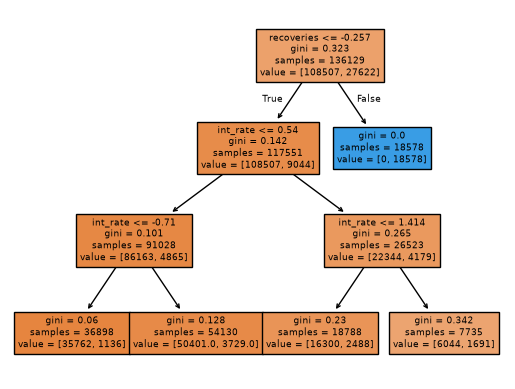

In [2]:
DTC=DecisionTreeClassifier(max_depth=3)
DTC.fit(x_train,y_train)
plot_tree(DTC, feature_names=x_train.columns, filled=True)
#if credit_score < X and income < Y, predict default

[Text(0.625, 0.875, 'recoveries <= -0.257\ngini = 0.323\nsamples = 136129\nvalue = [108507, 27622]'),
 Text(0.5, 0.625, 'int_rate <= 0.54\ngini = 0.142\nsamples = 117551\nvalue = [108507, 9044]'),
 Text(0.5625, 0.75, 'True  '),
 Text(0.25, 0.375, 'int_rate <= -0.71\ngini = 0.101\nsamples = 91028\nvalue = [86163, 4865]'),
 Text(0.125, 0.125, 'gini = 0.06\nsamples = 36898\nvalue = [35762, 1136]'),
 Text(0.375, 0.125, 'gini = 0.128\nsamples = 54130\nvalue = [50401.0, 3729.0]'),
 Text(0.75, 0.375, 'int_rate <= 1.414\ngini = 0.265\nsamples = 26523\nvalue = [22344, 4179]'),
 Text(0.625, 0.125, 'gini = 0.23\nsamples = 18788\nvalue = [16300, 2488]'),
 Text(0.875, 0.125, 'gini = 0.342\nsamples = 7735\nvalue = [6044, 1691]'),
 Text(0.75, 0.625, 'gini = 0.0\nsamples = 18578\nvalue = [0, 18578]'),
 Text(0.6875, 0.75, '  False')]

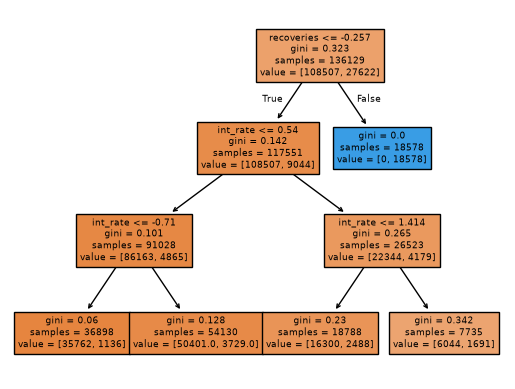

In [ ]:
DTC2=DecisionTreeClassifier(min_samples_leaf=20, class_weight="balanced", random_state=42)
DTC2.fit(x_train,y_train)
plot_tree(DTC, feature_names=x_train.columns, filled=True)

In [ ]:
RFC=RandomForestClassifier(n_estimators=200, min_samples_leaf=20, class_weight="balanced", n_jobs=-1, random_state=42)
RFC.fit(x_train, y_train)
roc_auc_score(y_test,  RFC.predict_proba(x_test)[:,1])

0.8895245803034928

In [5]:
RFC_preds=RFC.predict(x_test)
print(round(r2_score(y_test, RFC_preds), 3))
print(round(accuracy_score(y_test, RFC_preds), 3))

0.577
0.932


In [6]:
print(DTC2.feature_importances_)

[4.31631796e-02 4.23755106e-02 2.51180142e-02 4.57318930e-02
 6.20833675e-01 5.60928326e-02 7.54723975e-04 9.97702825e-04
 1.40521586e-03 5.02083411e-04 3.09804156e-04 1.29222713e-04
 3.20750710e-04 2.12874016e-04 2.17616130e-04 8.44152416e-04
 6.89253214e-04 2.65687348e-04 8.41744044e-04 2.21036272e-04
 1.67013623e-04 1.70231101e-04 8.29714522e-04 2.66792329e-04
 2.46808607e-04 3.73367167e-04 4.10288138e-04 2.23260847e-04
 2.04613720e-04 1.04303571e-03 3.55507465e-04 1.97944709e-04
 3.27648297e-04 3.80967790e-04 3.65672824e-04 7.56216228e-04
 3.29352236e-04 4.18612138e-04 3.23984153e-04 2.49077896e-04
 5.02908865e-04 3.91246781e-04 3.46220219e-04 4.36440316e-04
 4.26652885e-04 4.23953944e-04 6.58289242e-04 6.42218381e-04
 2.28615153e-04 2.62563631e-04 1.87640079e-04 5.79641877e-04
 6.02018557e-04 2.25576494e-04 7.13581763e-04 7.96630947e-04
 4.07350981e-04 2.07957809e-04 2.81072973e-04 6.79095051e-04
 2.24434524e-04 4.57826659e-04 2.99602840e-04 3.31048062e-04
 3.87683349e-04 5.952266

In [7]:
print(RFC.feature_importances_)

[5.31030283e-02 9.06243637e-02 2.65608360e-02 5.31277084e-02
 5.40348273e-01 5.97701416e-02 6.74450801e-04 9.53074586e-04
 1.17931548e-03 4.45696988e-04 4.24641451e-04 1.68748977e-04
 2.86943772e-04 2.15403959e-04 3.39486006e-04 9.78653252e-04
 7.42501378e-04 3.44703821e-04 1.01845827e-03 3.23323683e-04
 2.12548832e-04 2.19628796e-04 9.34751754e-04 2.75152553e-04
 3.39083652e-04 3.55993284e-04 5.28488805e-04 2.29051147e-04
 1.73569290e-04 1.00459249e-03 4.07403324e-04 1.92785858e-04
 3.54255658e-04 5.19936294e-04 4.89519235e-04 8.13863582e-04
 4.84405155e-04 3.71277052e-04 5.11138971e-04 2.78918949e-04
 5.24094981e-04 4.66213135e-04 3.63851579e-04 3.72762037e-04
 4.64947166e-04 4.79548439e-04 5.26961458e-04 6.19297021e-04
 2.67206519e-04 3.33163985e-04 2.42745725e-04 7.17230304e-04
 6.36078778e-04 2.41550469e-04 7.60998690e-04 7.72476395e-04
 4.47312144e-04 3.04448491e-04 3.09192275e-04 6.45304773e-04
 2.95795901e-04 4.29513202e-04 3.62917183e-04 4.19506191e-04
 4.16604545e-04 6.638086